# Palma (2022) Coursework — Data Preparation

This notebook works through Section 3 of the coursework brief in order. Data paths are relative to the project root, so the notebook can be run from either the project root or the `notebooks/` directory.

## 3.1 Load and inspect the data

Load the panel and descriptive datasets, then report their dimensions, column names, data types, country counts, and initial summaries.

In [1]:
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
DATA_DIR = PROJECT_ROOT / "data"

panel = pd.read_csv(DATA_DIR / "palma2022_panel.csv")
descriptive = pd.read_csv(DATA_DIR / "palma2022_descriptive.csv")

print(f"Panel dataset: {panel.shape[0]:,} rows × {panel.shape[1]} columns")
print(
    "Descriptive dataset: "
    f"{descriptive.shape[0]:,} rows × {descriptive.shape[1]} columns"
)

Panel dataset: 1,560 rows × 22 columns
Descriptive dataset: 311 rows × 12 columns


### Dataset columns and data types

The panel contains the country-year observations used in the regressions. The descriptive file contains the annual production and mint-output series used for figures.

In [2]:
print("Panel columns:")
print(panel.columns.tolist())
print("\nPanel data types:")
print(panel.dtypes.to_string())
print("\nDescriptive columns:")
print(descriptive.columns.tolist())
print("\nDescriptive data types:")
print(descriptive.dtypes.to_string())

Panel columns:
['year', 'country', 'cnumber', 'nominal_gdp_index', 'price_level_index', 'cpi_silver_index', 'real_gdp_index', 'precious_metals_prod_raw', 'war_with_spain', 'temperature', 'ln_real_gdp', 'ln_price', 'ln_nominal_gdp', 'ln_money_stock', 'metals_prod', 'metals_prod_ship', 'metals_prod_ship5y', 'metals_nologs', 'metals_nologs_ship_nocombat', 'cottington', 'ln_mint_adj', 'ln_mint_adj2']

Panel data types:
year                             int64
country                            str
cnumber                        float64
nominal_gdp_index              float64
price_level_index              float64
cpi_silver_index               float64
real_gdp_index                 float64
precious_metals_prod_raw       float64
war_with_spain                   int64
temperature                    float64
ln_real_gdp                    float64
ln_price                       float64
ln_nominal_gdp                 float64
ln_money_stock                 float64
metals_prod                    floa

### Observations by country

The panel should contain six countries with 260 years per country. This count is a quick check of the panel coverage.

In [3]:
country_counts = panel["country"].value_counts().sort_index()
print(country_counts.to_string())

country
England/GB    260
Germany       260
Holland       260
Italy         260
Portugal      260
Spain         260


### Initial inspection

Use `.head()`, `.info()`, and `.describe()` to inspect representative rows and numeric distributions in both datasets.

In [4]:
print("Panel preview:")
panel_preview = panel.head()
print(panel_preview.to_string(index=False))

print("\nDescriptive data preview:")
descriptive_preview = descriptive.head()
print(descriptive_preview.to_string(index=False))

Panel preview:
 year    country  cnumber  nominal_gdp_index  price_level_index  cpi_silver_index  real_gdp_index  precious_metals_prod_raw  war_with_spain  temperature  ln_real_gdp  ln_price  ln_nominal_gdp  ln_money_stock  metals_prod  metals_prod_ship  metals_prod_ship5y  metals_nologs  metals_nologs_ship_nocombat  cottington  ln_mint_adj  ln_mint_adj2
 1531 England/GB      1.0           8.453431          24.915076         34.334222       33.928979              22473.324219               0     0.371039     3.524270  3.215473        2.134572        8.393793    -5.281464         -5.281464           -5.281464       0.005085                     0.005085         0.0    -3.620439     -3.617676
 1532 England/GB      1.0           9.057339          25.642940         35.326222       35.320986              22786.191406               0    -0.374779     3.564477  3.244268        2.203575        8.406026    -5.279871         -5.279871           -5.279871       0.005093                     0.00509

In [5]:
print("Panel structure:")
panel.info()

Panel structure:
<class 'pandas.DataFrame'>
RangeIndex: 1560 entries, 0 to 1559
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   year                         1560 non-null   int64  
 1   country                      1560 non-null   str    
 2   cnumber                      1560 non-null   float64
 3   nominal_gdp_index            1560 non-null   float64
 4   price_level_index            1560 non-null   float64
 5   cpi_silver_index             1560 non-null   float64
 6   real_gdp_index               1560 non-null   float64
 7   precious_metals_prod_raw     1560 non-null   float64
 8   war_with_spain               1560 non-null   int64  
 9   temperature                  1560 non-null   float64
 10  ln_real_gdp                  1560 non-null   float64
 11  ln_price                     1560 non-null   float64
 12  ln_nominal_gdp               1560 non-null   float64
 13  ln_money_sto

In [6]:
print("Descriptive data structure:")
descriptive.info()

Descriptive data structure:
<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   311 non-null    int64  
 1   holland_mint_silver    280 non-null    float64
 2   france_mint_silver     259 non-null    float64
 3   genoa_mint_silver      280 non-null    float64
 4   innovation             69 non-null     float64
 5   silver_prod_tonnes     286 non-null    float64
 6   gold_prod_tonnes       280 non-null    float64
 7   total_prod_tonnes      280 non-null    float64
 8   gold_share             280 non-null    float64
 9   potosi_silver_tonnes   266 non-null    float64
 10  potosi_chart_top       311 non-null    float64
 11  england_mint_millions  280 non-null    float64
dtypes: float64(11), int64(1)
memory usage: 29.3 KB


In [7]:
print("Panel descriptive statistics:")
panel_summary = panel.describe().T
print(panel_summary.to_string())

print("\nDescriptive data statistics:")
descriptive_summary = descriptive.describe().T
print(descriptive_summary.to_string())

Panel descriptive statistics:
                              count           mean            std           min            25%            50%            75%            max
year                         1560.0    1660.500000      75.079048   1531.000000    1595.750000    1660.500000    1725.250000    1790.000000
cnumber                      1560.0       3.500000       1.708373      1.000000       2.000000       3.500000       5.000000       6.000000
nominal_gdp_index            1560.0      87.600940      45.762895      5.270340      52.818310      91.515321     114.851082     258.024884
price_level_index            1560.0      85.787323      30.849266     18.896794      65.845293      90.218422     102.342663     228.770655
cpi_silver_index             1560.0     102.664834      35.587230     10.617267      84.812192      95.682149     114.694701     309.460277
real_gdp_index               1560.0      96.182310      31.284580     26.496798      78.796972      94.736842     115.327794     1

### Section 3.1 checkpoint

The panel file is expected to contain 1,560 observations (six countries over 260 years). The descriptive file covers 311 years. Section 3.2 will check missingness directly before deciding whether any treatment is warranted.

## 3.2 Handle missing values

Count missing values by variable, check where panel missingness occurs across countries, and identify the year ranges affected in the descriptive series. The year spans help distinguish unrecorded historical observations from isolated gaps.

In [8]:
panel_missing = panel.isna().sum()
panel_missing = panel_missing[panel_missing.gt(0)]
panel_missing_report = panel_missing.rename("missing_rows").to_frame()
panel_missing_report["missing_percent"] = (
    panel_missing_report["missing_rows"] / len(panel) * 100
)

print("Panel variables with missing values:")
print(panel_missing_report.to_string())

panel_missing_by_country = panel.groupby("country")[panel_missing.index].apply(
    lambda group: group.isna().sum()
)
print("\nPanel missing counts by country:")
print(panel_missing_by_country.to_string())

key_panel_columns = [
    "year",
    "country",
    "nominal_gdp_index",
    "price_level_index",
    "real_gdp_index",
    "ln_real_gdp",
    "ln_price",
    "ln_nominal_gdp",
    "metals_prod_ship",
]
key_missing = panel[key_panel_columns].isna().sum()
print("\nMissing values in core panel analysis columns:")
print(key_missing.to_string())


def consecutive_year_ranges(years):
    """Format sorted years as compact inclusive ranges."""
    years = sorted(int(year) for year in years)
    if not years:
        return "None"

    ranges = []
    start = previous = years[0]
    for year in years[1:]:
        if year != previous + 1:
            ranges.append((start, previous))
            start = year
        previous = year
    ranges.append((start, previous))

    return ", ".join(
        str(start) if start == end else f"{start}–{end}"
        for start, end in ranges
    )


descriptive_missing_records = []
for column in descriptive.columns:
    missing_years = descriptive.loc[descriptive[column].isna(), "year"]
    if missing_years.empty:
        continue

    in_coursework_period = missing_years.between(1531, 1790)
    descriptive_missing_records.append(
        {
            "variable": column,
            "missing_rows": len(missing_years),
            "missing_years": consecutive_year_ranges(missing_years),
            "missing_1531_1790": int(in_coursework_period.sum()),
        }
    )

descriptive_missing_report = pd.DataFrame(descriptive_missing_records)
print("\nDescriptive variables with missing values and affected years:")
print(descriptive_missing_report.to_string(index=False))

Panel variables with missing values:
              missing_rows  missing_percent
cottington            1300        83.333333
ln_mint_adj           1301        83.397436
ln_mint_adj2          1301        83.397436

Panel missing counts by country:
            cottington  ln_mint_adj  ln_mint_adj2
country                                          
England/GB           0            1             1
Germany            260          260           260
Holland            260          260           260
Italy              260          260           260
Portugal           260          260           260
Spain              260          260           260

Missing values in core panel analysis columns:
year                 0
country              0
nominal_gdp_index    0
price_level_index    0
real_gdp_index       0
ln_real_gdp          0
ln_price             0
ln_nominal_gdp       0
metals_prod_ship     0

Descriptive variables with missing values and affected years:
             variable  missing_rows

### Missing-value treatment

Keep the original missing values as `NaN`; do not replace them with zero or interpolate them. The panel’s core GDP, price, year, country, and metals-shock columns are complete. Missing `cottington` and mint-output values are concentrated in country-specific fields that do not apply to most countries, with one missing England mint observation. Dropping those rows would discard valid panel observations.

In the descriptive series, missingness is concentrated in early or otherwise unavailable historical records. The primary gold, silver, and total-production measures are complete over 1531–1790; Potosí output is missing in 1531–1544, before the mine’s discovery. Treat these as unavailable observations rather than inferred zeros. Keep the full dataset, use the observations available for each variable, and let plots show gaps where a series is missing. For later analyses, restrict rows only when a required outcome or regressor is missing.

## 3.3 Understand and extend the variables

Sort the panel into country-year order, then construct annual percentage growth rates within each country. The first observation for each country has no prior year for comparison, so its growth value is naturally missing. The existing log variables remain the inputs for the local projections.

In [9]:
panel = panel.sort_values(["country", "year"]).reset_index(drop=True)

# Nominal GDP growth captures changes in current-price output and is useful
# for seeing how the total value of economic activity changes over time.
panel["nominal_gdp_growth"] = panel.groupby("country", sort=False)[
    "nominal_gdp_index"
].pct_change(fill_method=None)

# Real GDP growth measures annual output growth after adjusting for prices;
# it helps compare changes in economic activity across years.
panel["real_gdp_growth"] = panel.groupby("country", sort=False)[
    "real_gdp_index"
].pct_change(fill_method=None)

# Price growth is annual inflation, useful for tracking changes in the cost
# of the economy's output over time.
panel["price_growth"] = panel.groupby("country", sort=False)[
    "price_level_index"
].pct_change(fill_method=None)

growth_columns = [
    "nominal_gdp_growth",
    "real_gdp_growth",
    "price_growth",
]
print("Derived growth measures for the first three years of each country:")
growth_preview = panel[["country", "year", *growth_columns]].groupby(
    "country", sort=False
).head(3)
print(growth_preview.to_string(index=False))

print("\nGrowth-rate summary by country:")
growth_summary = panel.groupby("country", sort=False)[growth_columns].agg(
    ["mean", "std"]
)
print(growth_summary.round(4).to_string())

Derived growth measures for the first three years of each country:
   country  year  nominal_gdp_growth  real_gdp_growth  price_growth
England/GB  1531                 NaN              NaN           NaN
England/GB  1532            0.071439         0.041027      0.029214
England/GB  1533            0.035030         0.000947      0.034051
   Germany  1531                 NaN              NaN           NaN
   Germany  1532            0.022106         0.046039     -0.022880
   Germany  1533           -0.013815        -0.029505      0.016167
   Holland  1531                 NaN              NaN           NaN
   Holland  1532           -0.196516        -0.057054     -0.147900
   Holland  1533           -0.098912        -0.114396      0.017484
     Italy  1531                 NaN              NaN           NaN
     Italy  1532           -0.117647         0.000000     -0.117647
     Italy  1533            0.111415        -0.008403      0.120833
  Portugal  1531                 NaN             

The three new variables are percentage changes (so a value of `0.05` represents 5% growth). Their first-year values are missing by construction because no previous observation exists within that country. The log-level variables `ln_real_gdp`, `ln_price`, and `ln_nominal_gdp` are unchanged and remain the outcomes used in Section 4.4.

## 3.4 Display the dataset

The descriptive file contains annual series shared across countries, so join it to the prepared country-year panel on `year`. A left join preserves every panel observation; `many_to_one` validates that the descriptive file has at most one row per year. The merged table is convenient for country-specific comparisons alongside the common annual series.

In [10]:
merged_panel = panel.merge(
    descriptive,
    on="year",
    how="left",
    validate="many_to_one",
    suffixes=("", "_descriptive"),
)

print(
    "Merged panel: "
    f"{merged_panel.shape[0]:,} rows × {merged_panel.shape[1]} columns"
)
print(
    "Country-year coverage: "
    f"{merged_panel['country'].nunique()} countries, "
    f"{merged_panel['year'].min()}–{merged_panel['year'].max()}"
)
print("\nFull set of columns:")
print(merged_panel.columns.tolist())
print("\nMerged dataset structure:")
merged_panel.info()

sample_countries = ["England/GB", "Spain"]
merged_sample = merged_panel.loc[
    merged_panel["country"].isin(sample_countries)
].groupby("country", sort=False).head(3)

print("\nAll columns for three sample years in each selected country:")
with pd.option_context("display.max_columns", None, "display.width", 300):
    print(merged_sample.to_string(index=False))

Merged panel: 1,560 rows × 36 columns
Country-year coverage: 6 countries, 1531–1790

Full set of columns:
['year', 'country', 'cnumber', 'nominal_gdp_index', 'price_level_index', 'cpi_silver_index', 'real_gdp_index', 'precious_metals_prod_raw', 'war_with_spain', 'temperature', 'ln_real_gdp', 'ln_price', 'ln_nominal_gdp', 'ln_money_stock', 'metals_prod', 'metals_prod_ship', 'metals_prod_ship5y', 'metals_nologs', 'metals_nologs_ship_nocombat', 'cottington', 'ln_mint_adj', 'ln_mint_adj2', 'nominal_gdp_growth', 'real_gdp_growth', 'price_growth', 'holland_mint_silver', 'france_mint_silver', 'genoa_mint_silver', 'innovation', 'silver_prod_tonnes', 'gold_prod_tonnes', 'total_prod_tonnes', 'gold_share', 'potosi_silver_tonnes', 'potosi_chart_top', 'england_mint_millions']

Merged dataset structure:
<class 'pandas.DataFrame'>
RangeIndex: 1560 entries, 0 to 1559
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       -----------

The join retains the original 1,560 country-year observations. Year-level descriptive measures repeat across countries for the same year, while their missing values remain visible as `NaN`. The original `panel` and `descriptive` DataFrames remain available separately for analyses that call for them.

# 4 Questions and Analysis

This section reproduces the requested descriptive figures before moving on to the country series and local projections.

## 4.1 Precious metals production over time

Recreate Figure 2 using annual gold, silver, and total production in the Americas for 1531–1790. The total-production series is reported in silver-equivalent tonnes.

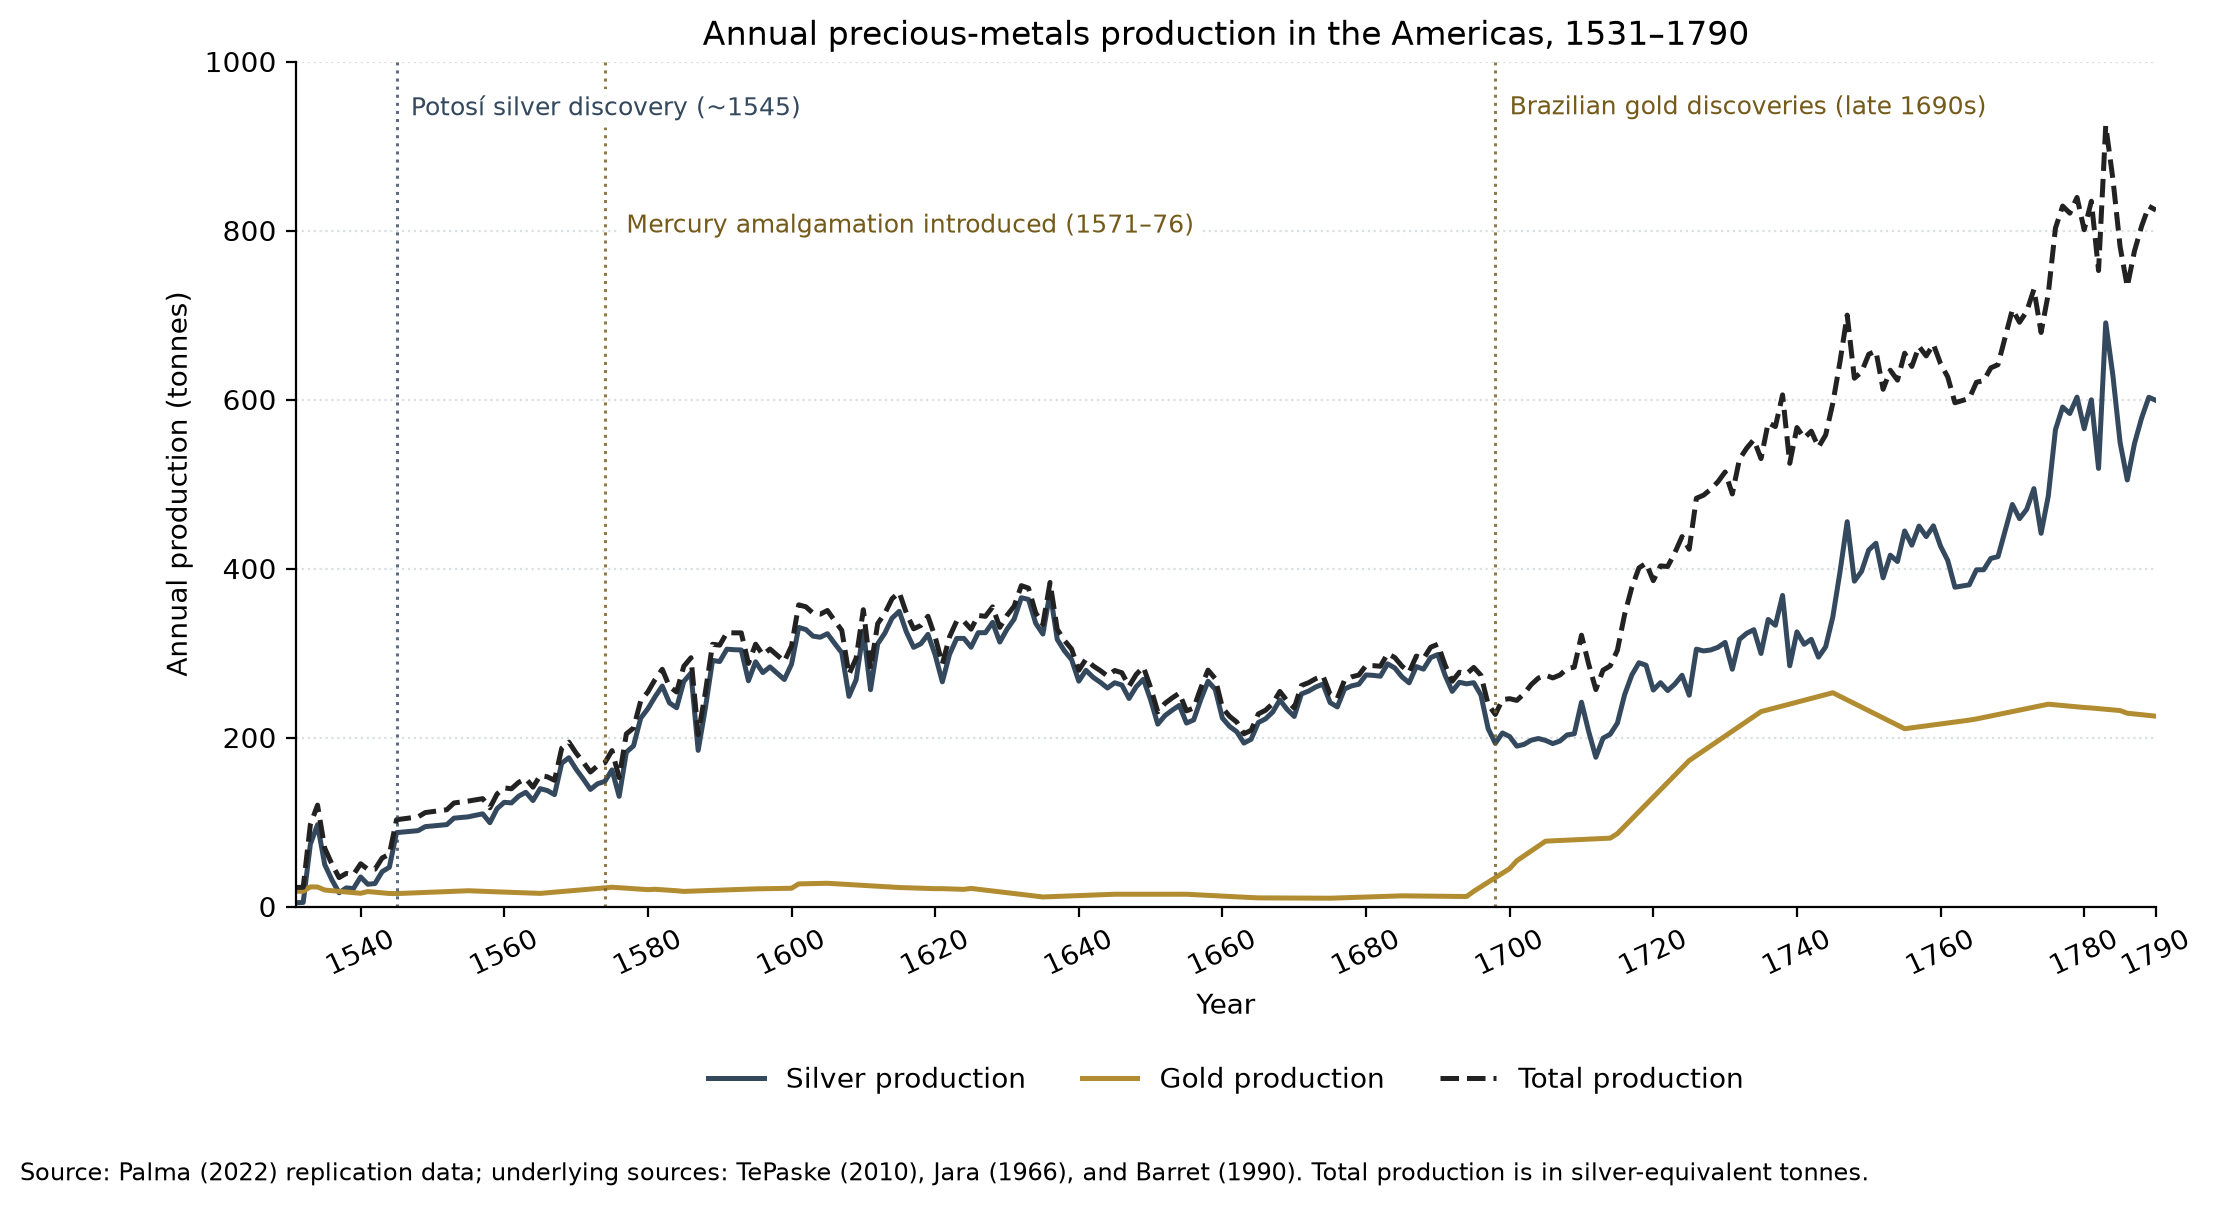

In [11]:
# SECTION 4: Questions and Analysis
# 4.1 Precious Metals Production Over Time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

metals_data = descriptive.loc[
    descriptive["year"].between(1531, 1790),
    [
        "year",
        "silver_prod_tonnes",
        "gold_prod_tonnes",
        "total_prod_tonnes",
    ],
].copy()

fig, ax = plt.subplots(figsize=(12, 6.5))
series = [
    ("silver_prod_tonnes", "Silver production", "#34495e", "-"),
    ("gold_prod_tonnes", "Gold production", "#b28c31", "-"),
    ("total_prod_tonnes", "Total production", "#222222", "--"),
]
for column, label, color, linestyle in series:
    ax.plot(
        metals_data["year"],
        metals_data[column],
        color=color,
        linestyle=linestyle,
        linewidth=1.8,
        label=label,
    )

events = [
    {
        "year": 1545,
        "label": "Potosí silver discovery (~1545)",
        "label_x": 1547,
        "label_y": 0.96,
        "color": "#34495e",
    },
    {
        "year": 1574,
        "label": "Mercury amalgamation introduced (1571–76)",
        "label_x": 1577,
        "label_y": 0.82,
        "color": "#755b1b",
    },
    {
        "year": 1698,
        "label": "Brazilian gold discoveries (late 1690s)",
        "label_x": 1700,
        "label_y": 0.96,
        "color": "#755b1b",
    },
]
for event in events:
    ax.axvline(
        event["year"],
        color=event["color"],
        linestyle=":",
        linewidth=1.1,
        alpha=0.8,
    )
    ax.text(
        event["label_x"],
        event["label_y"],
        event["label"],
        transform=ax.get_xaxis_transform(),
        fontsize=9,
        color=event["color"],
        ha="left",
        va="top",
        bbox={
            "boxstyle": "round,pad=0.25",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.94,
        },
    )

ax.set(
    title="Annual precious-metals production in the Americas, 1531–1790",
    xlabel="Year",
    ylabel="Annual production (tonnes)",
    xlim=(1531, 1790),
    ylim=(0, 1_000),
)
ax.set_xticks([*np.arange(1540, 1790, 20), 1790])
ax.set_yticks(np.arange(0, 1_001, 200))
ax.tick_params(axis="x", labelrotation=25)
ax.grid(axis="y", color="#d9dfe3", linestyle=":", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=3,
    frameon=False,
)

source_note = (
    "Source: Palma (2022) replication data; underlying sources: TePaske (2010), "
    "Jara (1966), and Barret (1990). Total production is in silver-equivalent tonnes."
)
fig.text(0.01, 0.015, source_note, ha="left", va="bottom", fontsize=8.5)
fig.subplots_adjust(bottom=0.23, top=0.88)

figure_dir = PROJECT_ROOT / "notebooks" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "figure_2_metals_production.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
fig

## 4.2 GDP and price level time series

Plot the three log-level outcomes over time, with all six countries shown in each panel. Each variable has its own shared vertical scale across countries, making the within-panel comparisons direct.

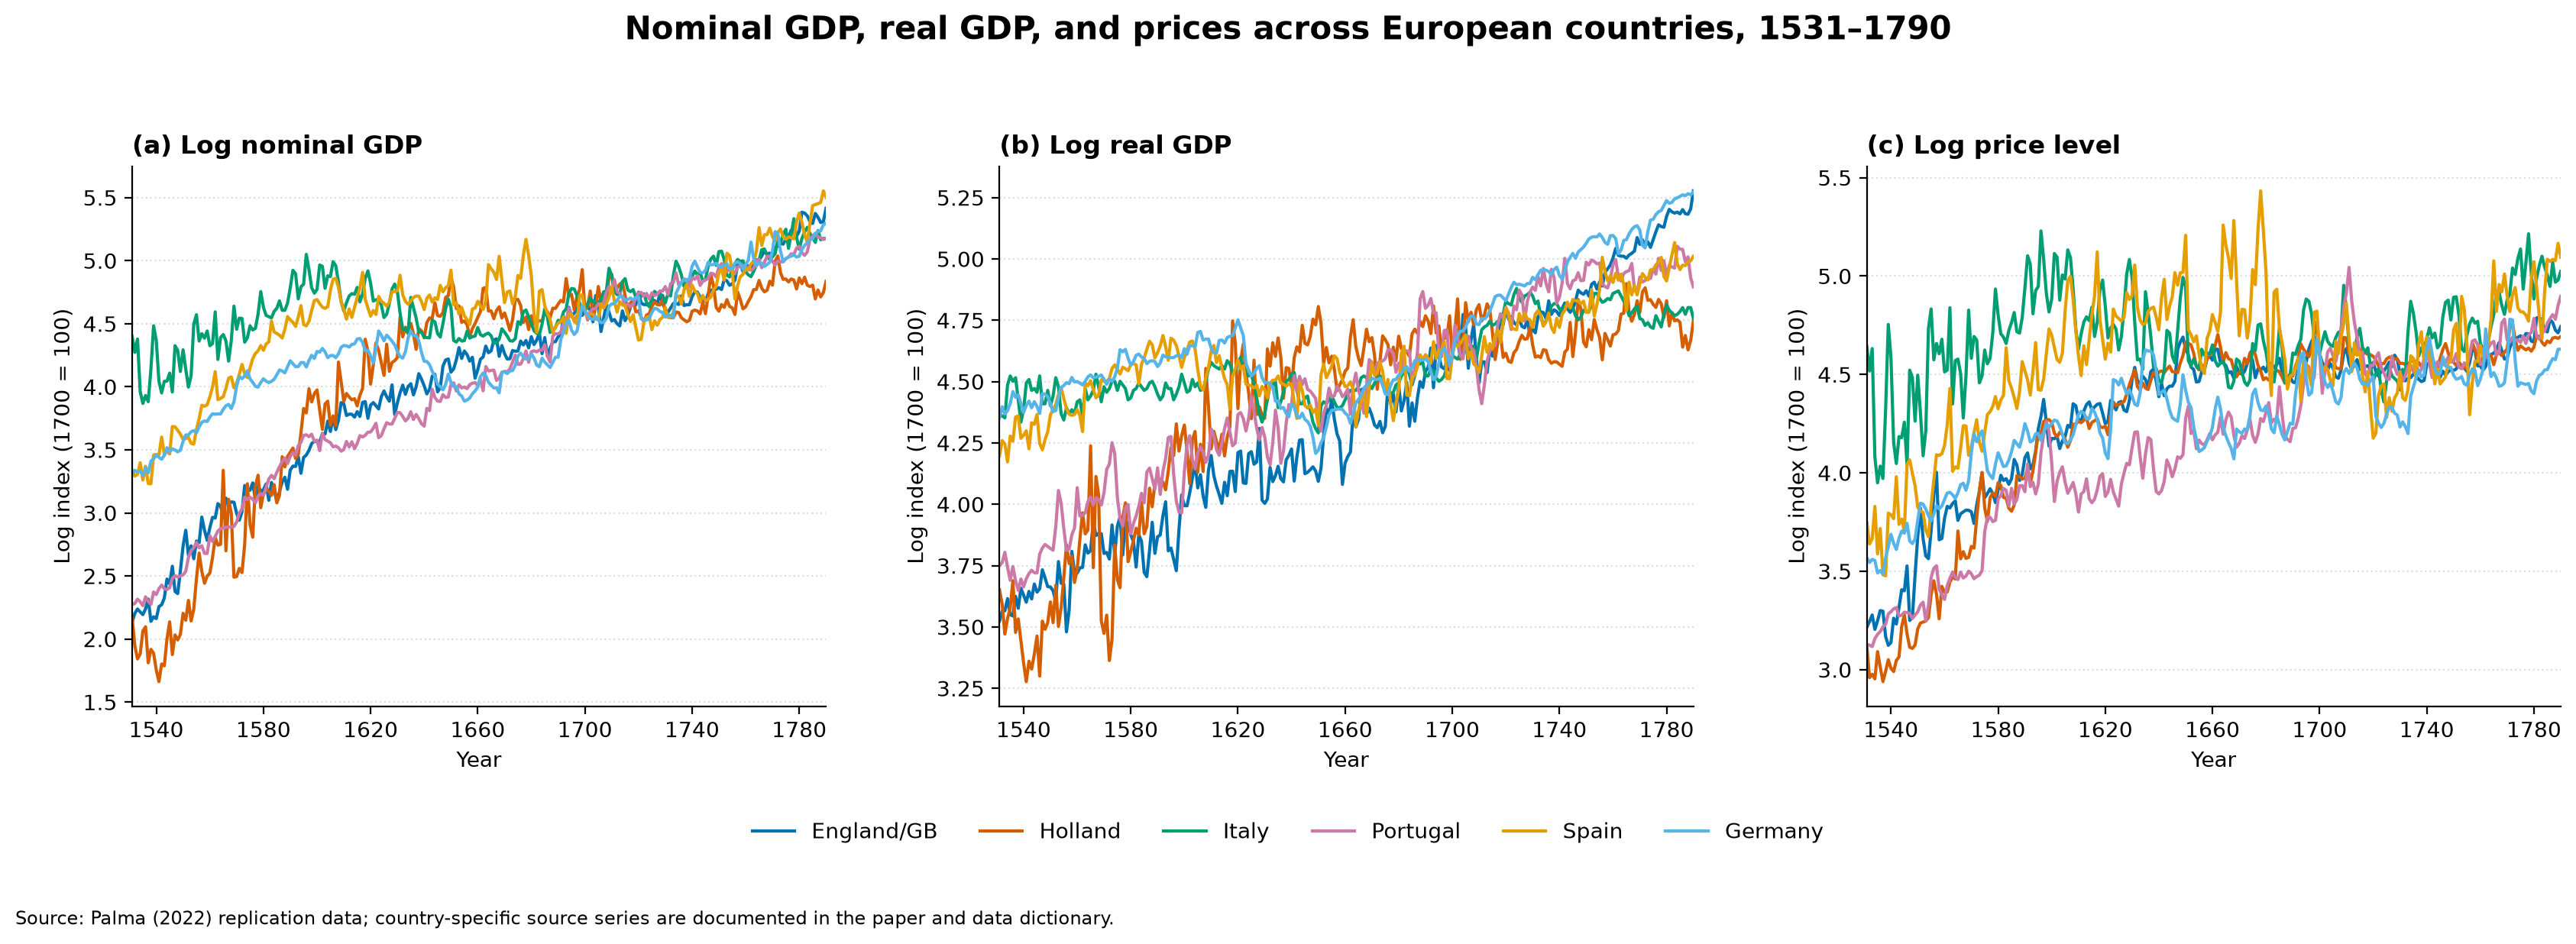

In [12]:
# 4.2 GDP and Price Level Time Series
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

country_order = [
    "England/GB",
    "Holland",
    "Italy",
    "Portugal",
    "Spain",
    "Germany",
]
country_colors = {
    "England/GB": "#0072b2",
    "Holland": "#d55e00",
    "Italy": "#009e73",
    "Portugal": "#cc79a7",
    "Spain": "#e69f00",
    "Germany": "#56b4e9",
}
outcomes = [
    ("ln_nominal_gdp", "(a) Log nominal GDP"),
    ("ln_real_gdp", "(b) Log real GDP"),
    ("ln_price", "(c) Log price level"),
]

fig, axes = plt.subplots(ncols=3, figsize=(17, 6.2), sharex=True)
for ax, (column, title) in zip(axes, outcomes, strict=True):
    for country in country_order:
        country_data = panel.loc[panel["country"].eq(country)]
        ax.plot(
            country_data["year"],
            country_data[column],
            color=country_colors[country],
            linewidth=1.5,
            label=country,
        )

    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Log index (1700 = 100)")
    ax.set_xlim(1531, 1790)
    ax.set_xticks(np.arange(1540, 1790, 40))
    ax.grid(axis="y", color="#d9dfe3", linestyle=":", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Nominal GDP, real GDP, and prices across European countries, 1531–1790",
    fontsize=15,
    fontweight="bold",
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.085),
    ncol=6,
    frameon=False,
)
source_note = (
    "Source: Palma (2022) replication data; country-specific source series "
    "are documented in the paper and data dictionary."
)
fig.text(0.01, 0.015, source_note, ha="left", va="bottom", fontsize=8.5)
fig.subplots_adjust(top=0.82, bottom=0.25, left=0.055, right=0.99, wspace=0.25)

figure_dir = PROJECT_ROOT / "notebooks" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "figures_4_to_6_gdp_price_levels.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
fig

## 4.3 Summary statistics and cross-country comparisons

Calculate country-level annual real GDP growth, inflation, and their standard deviations for the full sample and for the Silver Age (1531–1650) and Gold Age (1651–1790). Precious-metals production growth is the annual percentage change in total production from the descriptive data. Correlations are calculated separately for each country-period pair.

In [13]:
# 4.3 Summary Statistics and Cross-Country Comparisons
import pandas as pd

# Use annual total production for the descriptive correlation, not the
# shipping-adjusted monetary shock used later in the local projections.
metals_growth = descriptive[["year", "total_prod_tonnes"]].sort_values("year").copy()
metals_growth["metals_production_growth"] = metals_growth[
    "total_prod_tonnes"
].pct_change(fill_method=None)

analysis_panel = panel.merge(
    metals_growth[["year", "metals_production_growth"]],
    on="year",
    how="left",
    validate="many_to_one",
)
summary_periods = [
    ("Full sample (1531–1790)", 1531, 1790),
    ("Silver Age (1531–1650)", 1531, 1650),
    ("Gold Age (1651–1790)", 1651, 1790),
]
summary_countries = [
    "England/GB",
    "Holland",
    "Italy",
    "Portugal",
    "Spain",
    "Germany",
]

summary_records = []
for period, start_year, end_year in summary_periods:
    period_data = analysis_panel.loc[
        analysis_panel["year"].between(start_year, end_year)
    ]
    for country in summary_countries:
        country_data = period_data.loc[period_data["country"].eq(country)]
        paired_data = country_data[
            ["metals_production_growth", "real_gdp_growth"]
        ].dropna()
        summary_records.append(
            {
                "period": period,
                "country": country,
                "n_growth": country_data["real_gdp_growth"].count(),
                "mean_real_growth_pct": (
                    country_data["real_gdp_growth"].mean() * 100
                ),
                "sd_real_growth_pct": (
                    country_data["real_gdp_growth"].std() * 100
                ),
                "mean_inflation_pct": country_data["price_growth"].mean() * 100,
                "sd_inflation_pct": country_data["price_growth"].std() * 100,
                "corr_metal_growth_real_gdp": paired_data[
                    "metals_production_growth"
                ].corr(paired_data["real_gdp_growth"]),
                "n_correlation": len(paired_data),
            }
        )

summary_stats = pd.DataFrame(summary_records)
print("Country-level summary statistics (growth rates in percent):")
print(summary_stats.round(2).to_string(index=False))

country_average_stats = summary_stats.groupby("period", sort=False)[
    [
        "mean_real_growth_pct",
        "mean_inflation_pct",
        "corr_metal_growth_real_gdp",
    ]
].mean()
print("\nUnweighted average across the six country-level estimates:")
print(country_average_stats.round(3).to_string())

Country-level summary statistics (growth rates in percent):
                 period    country  n_growth  mean_real_growth_pct  sd_real_growth_pct  mean_inflation_pct  sd_inflation_pct  corr_metal_growth_real_gdp  n_correlation
Full sample (1531–1790) England/GB       259                  0.95                7.44                0.78              6.09                       -0.05            259
Full sample (1531–1790)    Holland       259                  1.08               11.70                0.75              5.40                       -0.07            259
Full sample (1531–1790)      Italy       259                  0.22                3.57                1.10             14.21                       -0.06            259
Full sample (1531–1790)   Portugal       259                  0.65                6.48                0.91              6.74                        0.01            259
Full sample (1531–1790)      Spain       259                  0.47                5.58              

### Reading the sub-period comparison

Across the six country-level estimates, mean annual inflation falls from 1.50% in the Silver Age to 0.48% in the Gold Age. Mean real GDP growth is similar (0.65% and 0.61%, respectively), although the country-specific changes are mixed. The average same-year correlation between raw metals-production growth and real GDP growth is -0.06 in the Silver Age and -0.06 in the Gold Age, both close to zero. These are descriptive correlations, not causal estimates; they do not capture delayed responses or the shipping-adjusted shock. Differences between periods could also reflect population, productivity, money demand, and country-specific conditions.

## 4.4 Local projections — impulse response functions

Estimate the simplified Jordà local projections for horizons 0–12. For each outcome, the dependent variable is `y[t+h] - y[t-1]`; regressions include the metals shock, two lags of that outcome, and country fixed effects. Standard errors are clustered by country.

Local projection coefficients and 95% confidence intervals:
outcome_label  horizon    beta  standard_error  ci_lower  ci_upper  observations  country_clusters
     Real GDP        0 -0.0039          0.0074   -0.0229    0.0151          1008                 6
     Real GDP        1 -0.0062          0.0059   -0.0213    0.0090          1008                 6
     Real GDP        2 -0.0020          0.0116   -0.0319    0.0279          1008                 6
     Real GDP        3  0.0035          0.0174   -0.0412    0.0482          1008                 6
     Real GDP        4  0.0016          0.0180   -0.0447    0.0479          1008                 6
     Real GDP        5 -0.0022          0.0189   -0.0509    0.0465          1008                 6
     Real GDP        6  0.0032          0.0225   -0.0545    0.0610          1008                 6
     Real GDP        7 -0.0011          0.0215   -0.0563    0.0541          1008                 6
     Real GDP        8 -0.0020          0.0179   

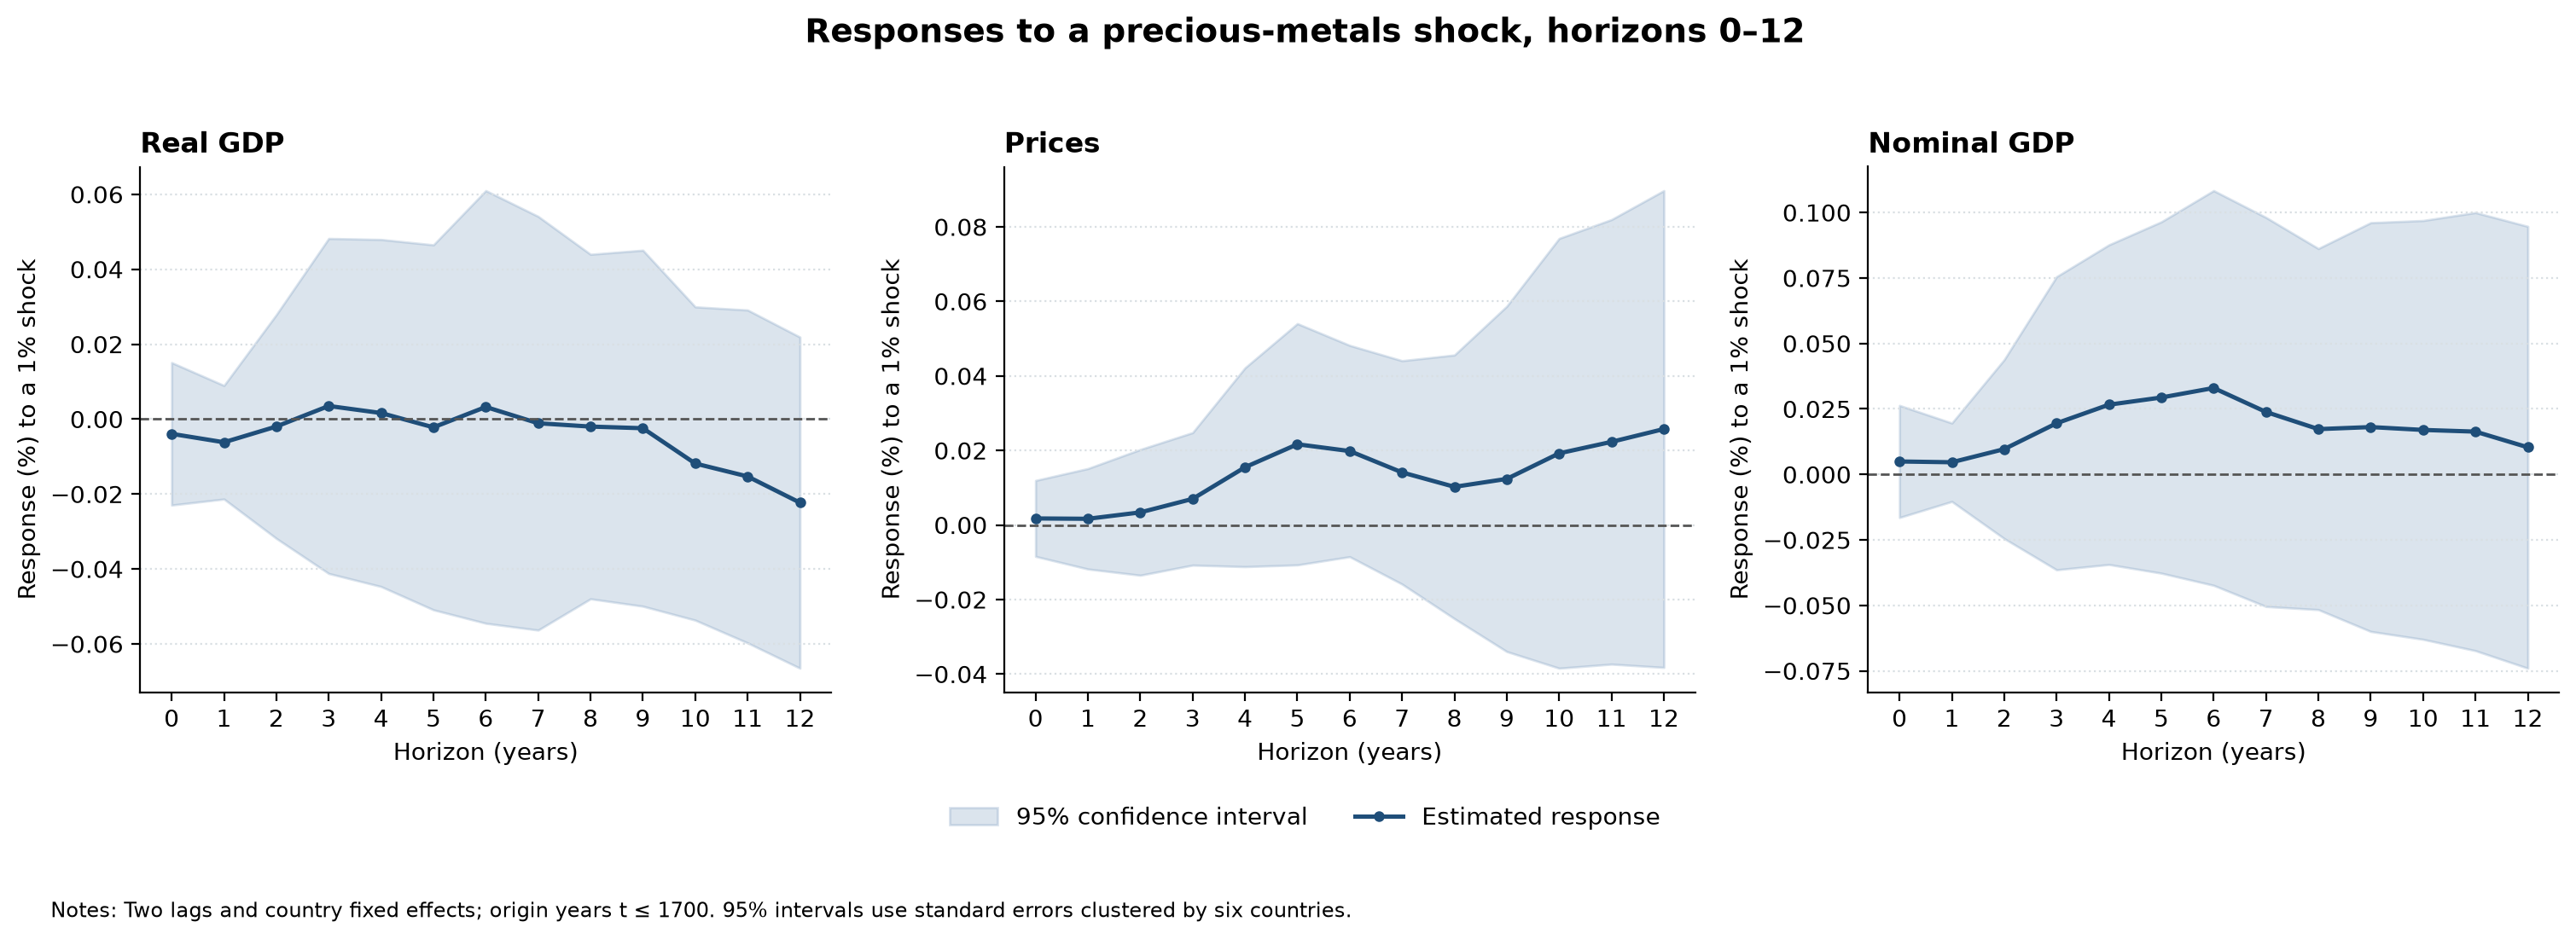

In [14]:
# 4.4 Local Projections — Impulse Response Functions
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf

outcomes = [
    ("ln_real_gdp", "Real GDP"),
    ("ln_price", "Prices"),
    ("ln_nominal_gdp", "Nominal GDP"),
]
maximum_horizon = 12

analysis_panel = panel.sort_values(["country", "year"]).reset_index(drop=True).copy()
for outcome, _ in outcomes:
    outcome_group = analysis_panel.groupby("country", sort=False)[outcome]
    analysis_panel[f"{outcome}_lag_1"] = outcome_group.shift(1)
    analysis_panel[f"{outcome}_lag_2"] = outcome_group.shift(2)

result_records = []
for outcome, outcome_label in outcomes:
    lag_1 = f"{outcome}_lag_1"
    lag_2 = f"{outcome}_lag_2"
    formula = (
        f"cumulative_change ~ metals_prod_ship + {lag_1} + {lag_2} "
        "+ C(country)"
    )

    for horizon in range(maximum_horizon + 1):
        # Leads and lags are formed within country before restricting origin years.
        future_outcome = analysis_panel.groupby("country", sort=False)[
            outcome
        ].shift(-horizon)
        regression_data = analysis_panel[
            ["year", "country", "cnumber", "metals_prod_ship", lag_1, lag_2]
        ].copy()
        regression_data["cumulative_change"] = (
            future_outcome - analysis_panel[lag_1]
        )
        regression_data = regression_data.loc[
            regression_data["year"].le(1700)
        ].dropna(
            subset=["cumulative_change", "metals_prod_ship", lag_1, lag_2]
        )

        fitted_model = smf.ols(formula, data=regression_data).fit(
            cov_type="cluster",
            cov_kwds={
                "groups": regression_data["cnumber"],
                "use_correction": True,
                "df_correction": True,
            },
            use_t=True,
        )
        confidence_interval = fitted_model.conf_int(alpha=0.05).loc[
            "metals_prod_ship"
        ]
        result_records.append(
            {
                "outcome": outcome,
                "outcome_label": outcome_label,
                "horizon": horizon,
                "beta": fitted_model.params["metals_prod_ship"],
                "standard_error": fitted_model.bse["metals_prod_ship"],
                "ci_lower": confidence_interval.iloc[0],
                "ci_upper": confidence_interval.iloc[1],
                "observations": int(fitted_model.nobs),
                "country_clusters": regression_data["cnumber"].nunique(),
            }
        )

lp_results = pd.DataFrame(result_records)
print("Local projection coefficients and 95% confidence intervals:")
print(
    lp_results[
        [
            "outcome_label",
            "horizon",
            "beta",
            "standard_error",
            "ci_lower",
            "ci_upper",
            "observations",
            "country_clusters",
        ]
    ].round(4).to_string(index=False)
)

fig, axes = plt.subplots(ncols=3, figsize=(15, 5.5), sharex=True)
for ax, (outcome, outcome_label) in zip(axes, outcomes, strict=True):
    outcome_results = lp_results.loc[lp_results["outcome"].eq(outcome)]
    horizons = outcome_results["horizon"]
    ax.fill_between(
        horizons,
        outcome_results["ci_lower"],
        outcome_results["ci_upper"],
        color="#4c78a8",
        alpha=0.20,
        label="95% confidence interval",
    )
    ax.plot(
        horizons,
        outcome_results["beta"],
        color="#1f4e79",
        marker="o",
        markersize=3.5,
        linewidth=1.8,
        label="Estimated response",
    )
    ax.axhline(0, color="#555555", linewidth=1, linestyle="--")
    ax.set_title(outcome_label, loc="left", fontweight="bold")
    ax.set_xlabel("Horizon (years)")
    ax.set_ylabel("Response (%) to a 1% shock")
    ax.set_xticks(range(maximum_horizon + 1))
    ax.grid(axis="y", color="#d9dfe3", linestyle=":", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Responses to a precious-metals shock, horizons 0–12",
    fontsize=14,
    fontweight="bold",
)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.09),
    ncol=2,
    frameon=False,
)
fig.text(
    0.01,
    0.015,
    "Notes: Two lags and country fixed effects; origin years t ≤ 1700. "
    "95% intervals use standard errors clustered by six countries.",
    ha="left",
    va="bottom",
    fontsize=8.5,
)
fig.subplots_adjust(top=0.82, bottom=0.26, left=0.045, right=0.99, wspace=0.25)

figure_dir = PROJECT_ROOT / "notebooks" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_dir / "figure_9_local_projection_irfs.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
fig

### Estimation notes

The estimation sample is selected by origin year `t ≤ 1700`; leads remain available through 1712 for the 12-year horizon. The plotted coefficients are on the log-log scale, so they are approximately percentage responses to a 1% increase in the metals-production-to-stock ratio. The simplified model follows the coursework option: two outcome lags and country fixed effects, without the additional trend, temperature, or war controls. Clustered inference uses six country clusters, so the confidence intervals should be read with caution.

## 4.5 Interpret the results

In [15]:
# 4.5 Interpretation of the impulse responses
# Real GDP estimates have mixed signs through year 9, then become more negative
# at years 10–12; they do not show a clear hump, and all 95% intervals include 0.
# Price estimates rise gradually from impact, but intervals include 0, so their
# timing is suggestive rather than statistically clear.
# Nominal GDP rises on impact, peaks around year 6, then declines; its intervals
# include 0 throughout.
# Palma's full model finds a clearer real GDP hump, peaking around years 6–9,
# with about a 0.9% rise by year 9 for a 10% metals shock. This simplified model
# does not reproduce that strong effect. Reduced controls and six clusters leave
# substantial uncertainty.